# Calorie Prediction Model

To create a model to develop a machine learning model using Python which can predict the number of calories a person has burnt during a workout based on some biological measures.

## Importing Libraries and loading the data

In [ ]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [ ]:
# loading the dataset
calories_data = pd.read_csv('calories.csv')

calories_data.head()

,User_ID,Calories
0,14733363,231.0
1,14861698,66.0
2,11179863,26.0
3,16180408,71.0
4,17771927,35.0


In [ ]:
features_data = pd.read_csv('exercise.csv')

features_data.head()

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8


In [ ]:
dataset = pd.concat([features_data, calories_data['Calories']], axis=1)

dataset.head()

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8,231.0
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3,66.0
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7,26.0
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5,71.0
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8,35.0


## Exploratory Data Analysis

In [ ]:
# data info on both sets

dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   User_ID     15000 non-null  int64  
 1   Gender      15000 non-null  object 
 2   Age         15000 non-null  int64  
 3   Height      15000 non-null  float64
 4   Weight      15000 non-null  float64
 5   Duration    15000 non-null  float64
 6   Heart_Rate  15000 non-null  float64
 7   Body_Temp   15000 non-null  float64
 8   Calories    15000 non-null  float64
dtypes: float64(6), int64(2), object(1)
memory usage: 1.0+ MB


In [ ]:
calories_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   User_ID   15000 non-null  int64  
 1   Calories  15000 non-null  float64
dtypes: float64(1), int64(1)
memory usage: 234.5 KB


In [ ]:
# check for duplicates

dataset.duplicated().sum()

0

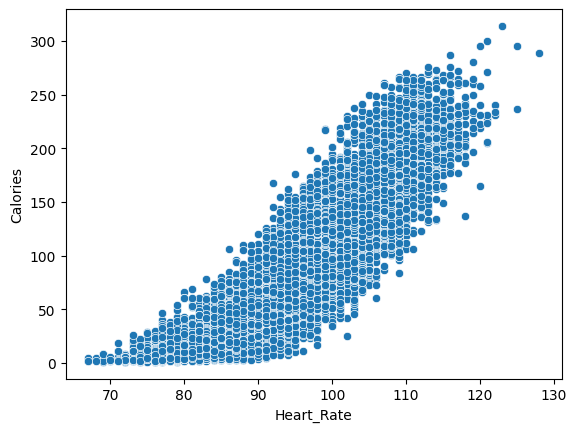

In [ ]:
sns.scatterplot(x="Heart_Rate", y="Calories", data=dataset)

plt.show()

## Matrix of Features and Dependent Variable Vector

In [ ]:
# matrix of features

dataset.columns

Index(['User_ID', 'Gender', 'Age', 'Height', 'Weight', 'Duration',
       'Heart_Rate', 'Body_Temp', 'Calories'],
      dtype='object')

In [ ]:
X = dataset.iloc[:, 1:8].values

print(X)

[['male' 68 190.0 ... 29.0 105.0 40.8]
 ['female' 20 166.0 ... 14.0 94.0 40.3]
 ['male' 69 179.0 ... 5.0 88.0 38.7]
 ...
 ['female' 43 159.0 ... 16.0 90.0 40.1]
 ['male' 78 193.0 ... 2.0 84.0 38.3]
 ['male' 63 173.0 ... 18.0 92.0 40.5]]


In [ ]:
# dependant variable vector

y = dataset.iloc[:, -1].values

print(y)

[231.  66.  26. ...  75.  11.  98.]


## Encoding Categorical Data

Convert the gender column into numberical data, male [0] and female [1] using the LabelEncoder.

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
X[:, 0] = le.fit_transform(X[:, 0])

print(X)

[[1 68 190.0 ... 29.0 105.0 40.8]
 [0 20 166.0 ... 14.0 94.0 40.3]
 [1 69 179.0 ... 5.0 88.0 38.7]
 ...
 [0 43 159.0 ... 16.0 90.0 40.1]
 [1 78 193.0 ... 2.0 84.0 38.3]
 [1 63 173.0 ... 18.0 92.0 40.5]]


## Spliting data using the Train Test Split Method

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [ ]:
print(X_train[0])

[1 78 197.0 101.0 8.0 95.0 39.5]


In [ ]:
print(X_test[0])

[0 27 170.0 66.0 9.0 94.0 39.8]


In [ ]:
print(y_train[0])

57.0


In [ ]:
print(y_test[0])

43.0


## Feature Scaling

Scale data so that features do not overpower each other.

In [ ]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train[:, 1:] = sc.fit_transform(X_train[:, 1:])
X_test[:, 1:] = sc.transform(X_test[:, 1:])

In [ ]:
print(X_train[0])

[1 2.067918420700965 1.573600524902042 1.7266860157525448
 -0.9030383153264778 -0.05180126670340685 -0.6701000022473131]


In [ ]:
print(X_test[0])

[0 -0.9318565746627003 -0.3189046441876168 -0.6010712692117908
 -0.782820212553927 -0.1559942268845794 -0.28597235967939844]


## Models

### Linear Regression Models

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# initialize and train the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

LinearRegression()

In [ ]:
# make predictions on the test set
lr_y_pred = lr_model.predict(X_test)

In [ ]:
# Evaluation
mae_lr = mean_absolute_error(y_test, lr_y_pred)
mse_lr = mean_squared_error(y_test, lr_y_pred)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, lr_y_pred)

print(f"Linear Regression - MAE: {mae_lr}, RMSE: {rmse_lr}, R² Score: {r2_lr}")

Linear Regression - MAE: 8.090679636313181, RMSE: 10.899116757510997, R² Score: 0.969214323020104


### XG Boost

In [ ]:
import xgboost as xgb

# Initialize and train model
xgb_model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, learning_rate=0.1)
xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.1, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=100, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [ ]:
# Predictions
y_pred_xgb = xgb_model.predict(X_test)

In [ ]:
# Evaluation
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print(f"XGBoost Regression - MAE: {mae_xgb}, RMSE: {rmse_xgb}, R² Score: {r2_xgb}")

XGBoost Regression - MAE: 1.2481488135258356, RMSE: 1.823952683843058, R² Score: 0.9991378293512151


## Predict Calories

In [ ]:
# Function to take user input
def get_user_input():
    print("\nEnter details to predict calories burned:")

    gender = input("Gender (0 = Female, 1 = Male): ")
    age = float(input("Age: "))
    height = float(input("Height (cm): "))
    weight = float(input("Weight (kg): "))
    duration = float(input("Duration of exercise (minutes): "))
    heart_rate = float(input("Heart Rate (bpm): "))
    body_temp = float(input("Body Temperature (°C): "))

    # Convert gender input to float
    gender = float(gender)

    # Create a NumPy array with user input
    user_data = np.array([[gender, age, height, weight, duration, heart_rate, body_temp]])



    return user_data

In [ ]:
# Take user input and scale
user_input = get_user_input()

# Predict using the trained model
predicted_calories = xgb_model.predict(user_input)

print(f"\n🔥 Estimated Calories Burned: {predicted_calories[0]:.2f} kcal 🔥")


Enter details to predict calories burned:
Gender (0 = Female, 1 = Male): 1
Age: 24
Height (cm): 167
Weight (kg): 82
Duration of exercise (minutes): 60
Heart Rate (bpm): 146
Body Temperature (°C): 37

🔥 Estimated Calories Burned: 243.21 kcal 🔥
